## Packages

In [730]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm

## How has the number of medals won by different countries changed over time? What trends can be observed?

In [ ]:
olympics = pd.read_csv("olympics.csv")
medalists = olympics[olympics['medal'].notna()]
medalists = medalists[medalists['season']=='Summer']

### Change of number of countries and number of medalist by Event

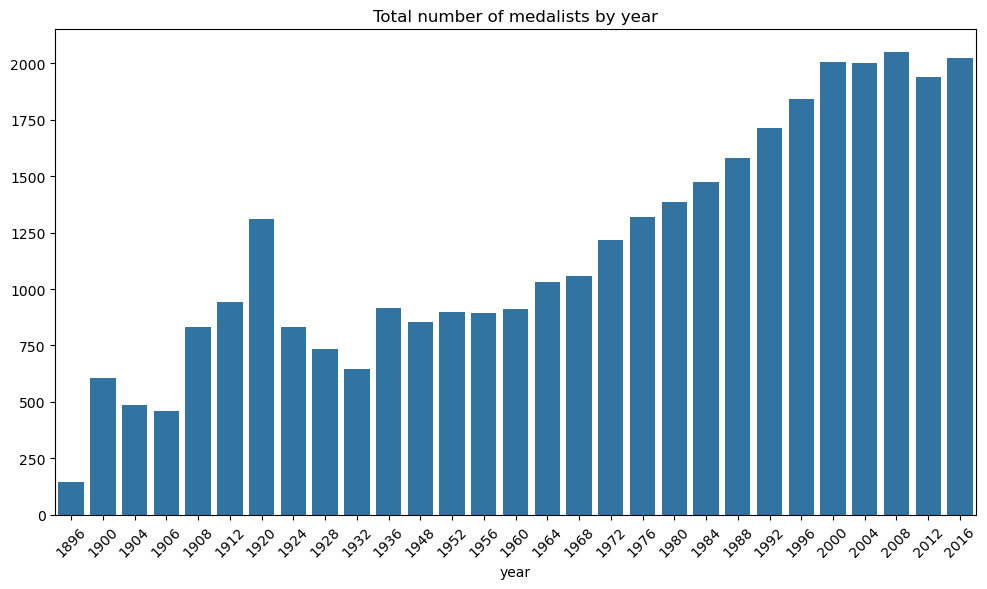

In [648]:
total_medals_year = medalists.groupby('year').size()
countries_per_year = olympics[olympics['season']=='Summer'].groupby('year')['noc'].nunique().reset_index(name='num_countries')

plt.figure(figsize=(10, 6))
sns.barplot(data=total_medals_year)
plt.title('Total number of medalists by year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- The number of medalists in the Summer Olympics steadily increased over time, driven by the growing number of sports and events. However, the 1920 Summer Olympics experienced an exceptional spike in medalists, likely due to the post-World War I resurgence and an expanded event lineup aimed at revitalizing the Olympic movement. This surge was followed by a decline in subsequent years as the program stabilized.
- The 1906 Intercalated Games in Athens aimed to revive the Olympics after the poorly received 1900 and 1904 events. Though they boosted interest and set organizational standards, they were later excluded from the official Olympic roster for not aligning with the 4-year cycle.
- The 1916, 1940, and 1944 Olympics were canceled due to the global conflicts of World War I (1914–1918) and World War II (1939–1945).
  

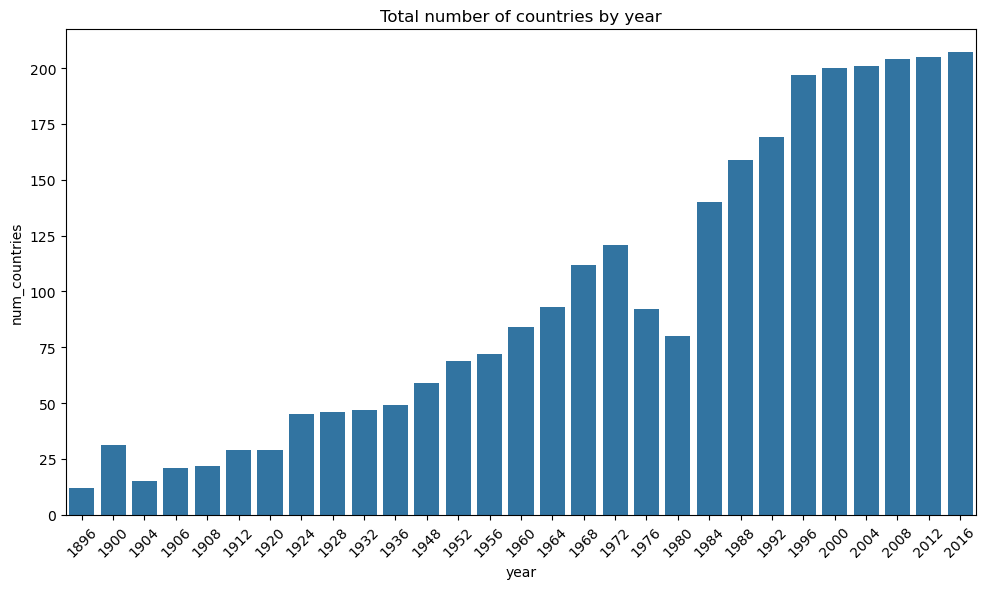

In [650]:
plt.figure(figsize=(10, 6))
sns.barplot(data=countries_per_year, x='year', y='num_countries')
plt.title('Total number of countries by year')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- The number of countries participating in each Summer Olympics steadily increased as the Games grew in popularity and the world became more interconnected. However, participation dropped in 1976 and 1980 due to political boycotts.
- In 1976, 29 countries, primarily from Africa, boycotted the Montreal Games after the IOC refused to ban New Zealand for its rugby team's tour of apartheid-era South Africa, which violated a United Nations call for a sporting embargo.
- In 1980, participation fell further as 66 countries, led by the United States, boycotted the Moscow Games in protest of the Soviet Union's invasion of Afghanistan. This resulted in only 80 nations competing, the lowest since 1956.

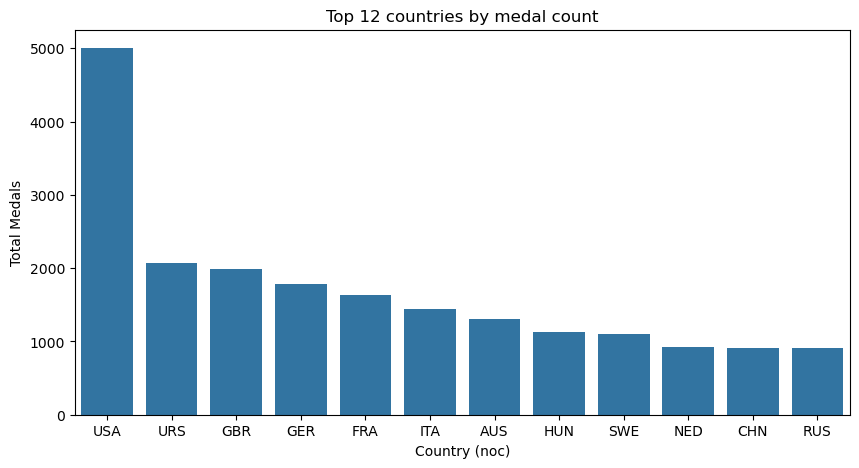

In [661]:

total_medals = medalists.groupby(by='noc').size().reset_index(name = 'Total Medals')
total_medals = total_medals.sort_values(by='Total Medals', ascending = False).head(12).reset_index(drop=True)

plt.figure(figsize=(10, 5))
sns.barplot(data = total_medals, x = 'noc', y = 'Total Medals') 
plt.title("Top 12 countries by medal count")
plt.xlabel('Country (noc)')
plt.show()

- The barplot displays the top 12 countries with the highest total medal counts across all years. Historical and geographical factors play a significant role in these rankings, including the periods of activity for the USSR and Russia, among others. 

    1. USA
    2. URS (Soviet Union)
    3. GBR (Great Britain)
    4. GER (Germany)
    5. FRA (France)
    6. ITA (Italy)
    7. AUS (Australia)
    8. HUN (Hungary)
    9. SWE (Sweden)
    10. NED (Netherlands)
    11. CHN (China)
    12. RUS (Russia)


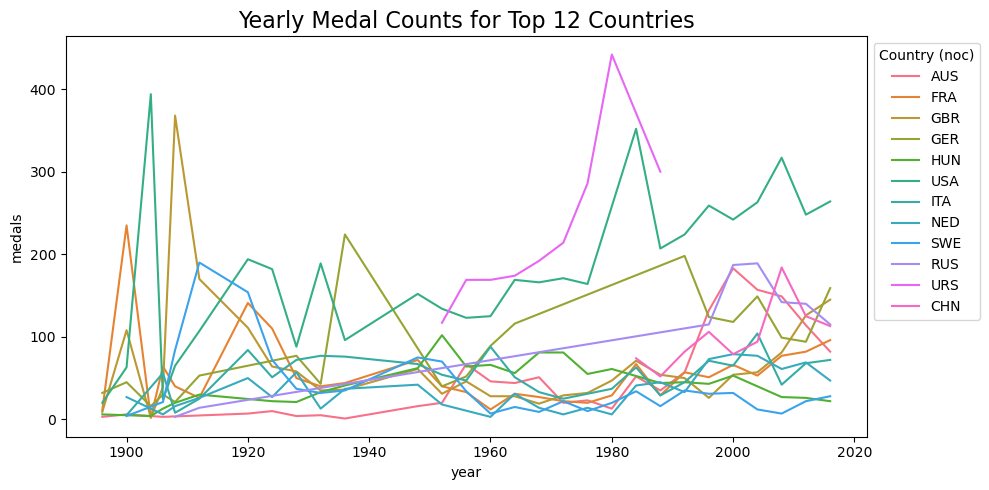

In [514]:
top12 = medalists[medalists['noc'].isin(total_medals['noc'])]
top12 = top12.groupby(['year','noc']).size().reset_index(name = 'medals')

plt.figure(figsize=(10, 5))
sns.lineplot(data = top12, x = 'year', y = 'medals', hue = 'noc')
plt.title("Yearly Medal Counts for Top 12 Countries", fontsize=16)
plt.legend(title="Country (noc)", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


  
- The line plot shows the yearly medal counts for the top 12 countries in the history of the Summer Olympics. It highlights fluctuations in medal performance over time, with noticeable peaks for certain countries like the USSR and the USA during specific periods. Historical factors such as the Cold War, boycotts, and changes in the number of events likely influenced these trends. The data also reflects periods of dominance by specific nations, such as China's rise in recent decades.

In [673]:

total_medal_year = pd.DataFrame(medalists.groupby('year').size())
total_medal_year = total_medal_year.reset_index(names = 'year')
total_medal_year.columns = ['year','year_medals']
prop_by_year =  pd.merge( left = top12, right = total_medal_year, on = 'year', how = 'outer')
prop_by_year = prop_by_year.assign( proportion = prop_by_year['medals']/prop_by_year['year_medals'])
grouped = prop_by_year.groupby(['year', 'noc'])
result = grouped['proportion'].sum().reset_index()
prop_by_year_sorted = prop_by_year.sort_values(by=['year', 'proportion'], ascending=[True, False])
top10_by_year = prop_by_year_sorted.groupby('year').head(10).reset_index(drop=True)
pivot_top = top10_by_year.pivot(index='year', columns='noc', values='proportion').fillna(0)

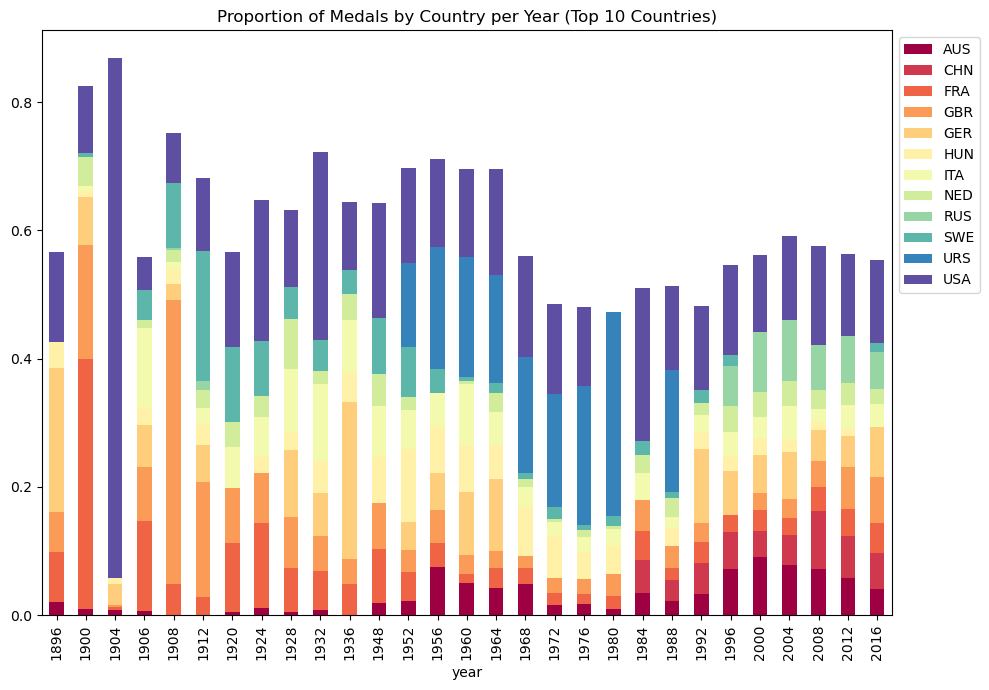

In [679]:

pivot_top.plot(kind='bar', stacked=True, figsize=(10, 7), colormap='Spectral')
plt.title("Proportion of Medals by Country per Year (Top 10 Countries)")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()


- This stacked bar plot shows the proportion of medals won by the top 10 countries in each Olympic year. Each bar represents the total proportion of medals for that year, broken down by the contributions of the top-performing countries. Over time, the shrinking height of the bars indicates that countries outside the top 10 are increasingly winning medals, reflecting a growing diversity in global athletic success. Notably, the dominance of certain countries like the USA and USSR during specific periods is evident, with their proportions decreasing as other nations improve their performances in later years
- The 1904 Summer Olympics, held in St. Louis, saw minimal international participation, with only 69–74 athletes from outside North America out of 651 total competitors and representation from just 12–15 nations. Travel difficulties and tensions from the Russo-Japanese War further limited participation, resulting in a competition largely dominated by the United States.

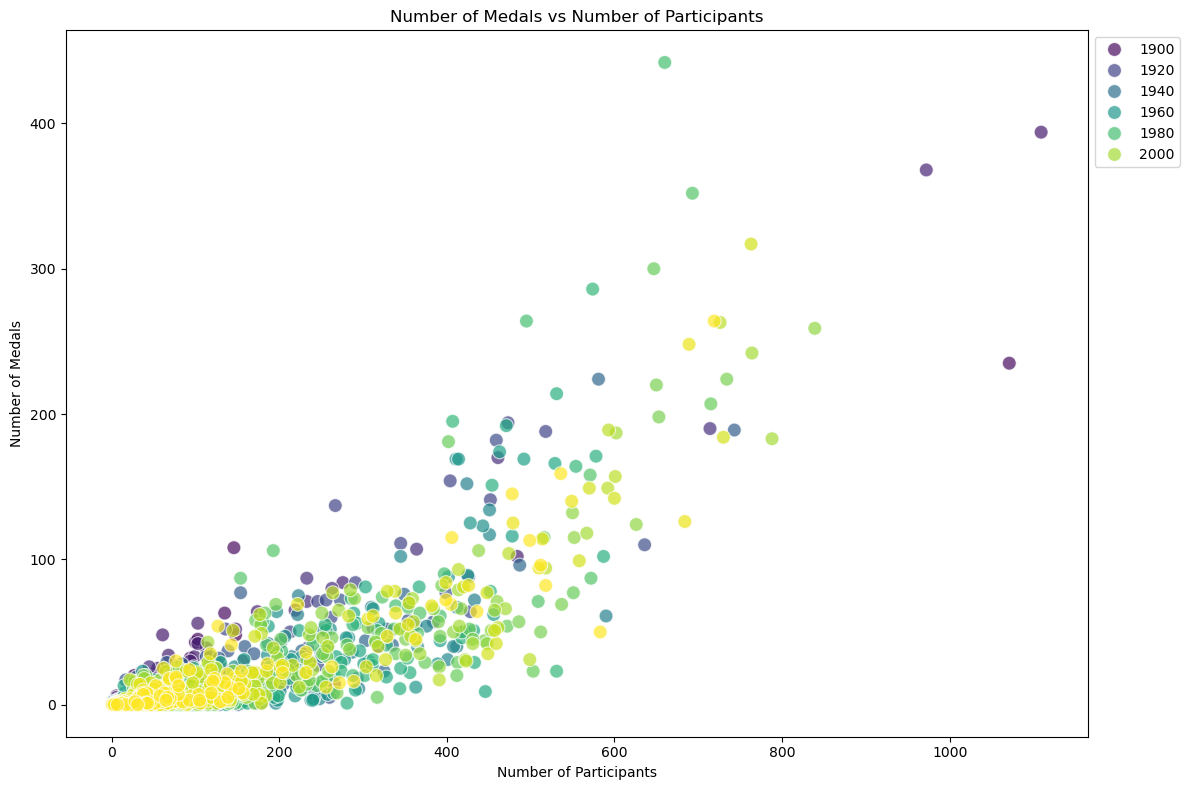

In [799]:


summer_olympics = olympics[olympics['season'] == 'Summer']
participants = summer_olympics.groupby(['year', 'noc']).size().reset_index(name='participants')
medals = medalists.groupby(['year', 'noc']).size().reset_index(name='medals')
participant_medals = pd.merge(participants, medals, on=['year', 'noc'], how='outer').fillna(0)

plt.figure(figsize=(12, 8))
sns.scatterplot(data=participant_medals, x='participants', y='medals', hue='year', palette='viridis', s=100, alpha=0.7)
plt.title("Number of Medals vs Number of Participants")
plt.xlabel("Number of Participants")
plt.ylabel("Number of Medals")
plt.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()



- This scatterplot displays the relationship between the number of participants and the number of medals won by countries in the Summer Olympics over different years. Each point represents a country in a specific year, with the color indicating the year. The plot shows a general positive correlation: countries with more participants tend to win more medals. Outliers, such as points with high medal counts relative to participants or vice versa, likely represent dominant countries or specific historical contexts.